# Projet C05 — Prédiction de la résiliation d'abonnement Internet (Churn)

**Type :** Apprentissage supervisé — Classification binaire

**Contexte :** Un opérateur télécom fictif souhaite identifier les clients susceptibles de résilier leur abonnement internet dans les 30 prochains jours afin de mettre en place des actions de fidélisation ciblées.

**Données :** Synthétiques, volontairement « sales » — contexte sénégalais (montants en FCFA, régions du Sénégal).

---

## Étape 0 — Imports et configuration

In [1]:
# ============================================================
# Imports
# ============================================================
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, precision_recall_curve, f1_score,
    precision_score, recall_score, RocCurveDisplay
)
from sklearn.calibration import CalibrationDisplay

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('Imports terminés.')

Imports terminés.


---
## Étape 1 — Contrat de prédiction

| Élément | Description |
|---------|-------------|
| **Qui prédit ?** | Un modèle de classification binaire |
| **Quoi ?** | La probabilité qu'un client résilie son abonnement internet dans les 30 prochains jours |
| **Pour qui ?** | L'équipe fidélisation de l'opérateur télécom |
| **Quand ?** | Chaque mois, à partir des données disponibles à la date d'observation |
| **Variable cible** | `resiliation_30j` ∈ {0, 1} — classe positive = 1 (résiliation) |
| **Variables autorisées** | Toutes sauf `client_id` (identifiant) et `mois_reference` (risque de fuite temporelle) |
| **Métrique principale** | Average Precision (AP) — adaptée au déséquilibre de classes |
| **Contrainte métier** | L'opérateur ne peut contacter que **25 % de ses clients** au maximum |

### Risque de fuite de données

`mois_reference` indique *quand* l'observation a été faite, pas une caractéristique intrinsèque du client. L'inclure comme variable prédictive serait une **fuite temporelle**. Cette colonne sera conservée pour l'audit mais exclue de la modélisation.

---
## Étape 2 — Chargement et audit des données

In [2]:
# Recherche automatique du fichier de données
data_files = (
    glob.glob("../**/P05_churn_internet_sale.csv", recursive=True)
)
if not data_files:
    raise FileNotFoundError("Fichier P05_churn_internet_sale.csv introuvable.")

DATA_PATH = data_files[0]
print(f"Fichier trouvé : {DATA_PATH}")

Fichier trouvé : ..\projet apprentissage supervisé étudaint\projet apprentissage supervise╠ü e╠ütudaint\Pack_15_Projets_Classification\P05_churn_internet\P05_churn_internet_sale.csv


In [3]:
# Chargement brut — toutes les colonnes en texte pour l'audit
df_brut = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
print(f"Dimensions : {df_brut.shape[0]} lignes × {df_brut.shape[1]} colonnes")
print(f"\nColonnes : {list(df_brut.columns)}")
df_brut.head()

Dimensions : 1725 lignes × 15 colonnes

Colonnes : ['client_id', 'mois_reference', 'region', 'type_offre', 'anciennete_mois', 'facture_moy_fcfa', 'retards_paiement_6m', 'incidents_reseau_30j', 'debit_moy_mbps', 'tickets_support_90j', 'satisfaction_score', 'usage_go_30j', 'changement_tarif_3m', 'mode_paiement', 'resiliation_30j']


,client_id,mois_reference,region,type_offre,anciennete_mois,facture_moy_fcfa,retards_paiement_6m,incidents_reseau_30j,debit_moy_mbps,tickets_support_90j,satisfaction_score,usage_go_30j,changement_tarif_3m,mode_paiement,resiliation_30j
0,CLI00000,2025-06-01 00:00:00,Dakar,Fibre,72,35281.00 FCFA,1,1,46.1,0,3.0,19.0,Non,Prelevement,0
1,CLI00001,2025-12-01 00:00:00,Kaolack,ADSL,27,18663.0,2,3,900,1,1.0,73.7,Non,Prelevement,0
2,CLI00002,2026-06-01 00:00:00,Kaolack,FIBRE,60,27990.0,2,1,,1,5.0,37.9,Non,Wave,0
3,CLI00003,2026-06-01 00:00:00,Dakar,Fibre,60,38245.0,0,4,6.9,1,,50.1,Non,OrangeMoney,0
4,CLI00004,2026-01-01 00:00:00,Dakar,Fibre,7,15425.0,1,0,44.9,2,1.0,60.7,Non,Prelevement,0


In [4]:
# Chargement avec types automatiques pour exploration
df = pd.read_csv(DATA_PATH)
print("Types des colonnes :")
print(df.dtypes)
print(f"\nDimensions : {df.shape}")

Types des colonnes :
client_id                   str
mois_reference              str
region                      str
type_offre                  str
anciennete_mois           int64
facture_moy_fcfa            str
retards_paiement_6m       int64
incidents_reseau_30j      int64
debit_moy_mbps              str
tickets_support_90j       int64
satisfaction_score      float64
usage_go_30j            float64
changement_tarif_3m         str
mode_paiement               str
resiliation_30j           int64
dtype: object

Dimensions : (1725, 15)


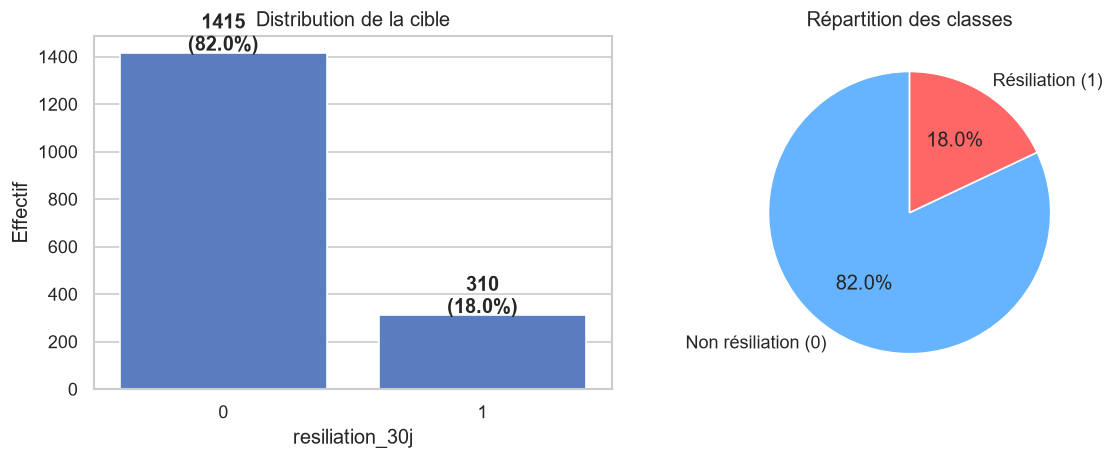

Classe 0 (pas de résiliation) : 1415 (82.0%)
Classe 1 (résiliation) :        310 (18.0%)
Ratio de déséquilibre : 1:4.6


In [5]:
# Distribution de la variable cible
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cible_counts = df['resiliation_30j'].value_counts()
cible_pct = df['resiliation_30j'].value_counts(normalize=True) * 100

sns.countplot(x='resiliation_30j', data=df, ax=axes[0])
axes[0].set_title('Distribution de la cible')
axes[0].set_xlabel('resiliation_30j')
axes[0].set_ylabel('Effectif')
for i, (v, p) in enumerate(zip(cible_counts.values, cible_pct.values)):
    axes[0].text(i, v + 10, f'{v}\n({p:.1f}%)', ha='center', fontweight='bold')

axes[1].pie(cible_counts.values, labels=['Non résiliation (0)', 'Résiliation (1)'],
            autopct='%1.1f%%', startangle=90, colors=['#66b3ff', '#ff6666'])
axes[1].set_title('Répartition des classes')

plt.tight_layout()
plt.show()

print(f"Classe 0 (pas de résiliation) : {cible_counts[0]} ({cible_pct[0]:.1f}%)")
print(f"Classe 1 (résiliation) :        {cible_counts[1]} ({cible_pct[1]:.1f}%)")
print(f"Ratio de déséquilibre : 1:{cible_counts[0]/cible_counts[1]:.1f}")

In [6]:
# Valeurs manquantes
manquants = df.isnull().sum()
manquants_pct = (df.isnull().sum() / len(df) * 100).round(2)
tableau_manquants = pd.DataFrame({
    'Manquants': manquants,
    'Pourcentage (%)': manquants_pct
}).sort_values('Manquants', ascending=False)
print("Valeurs manquantes par colonne :")
tableau_manquants[tableau_manquants['Manquants'] > 0]

Valeurs manquantes par colonne :


,Manquants,Pourcentage (%)
mode_paiement,52,3.01
debit_moy_mbps,50,2.90
satisfaction_score,50,2.90


In [7]:
# Statistiques descriptives — variables numériques
df.describe()

,anciennete_mois,retards_paiement_6m,incidents_reseau_30j,tickets_support_90j,satisfaction_score,usage_go_30j,resiliation_30j
count,1725.000000,1725.000000,1725.000000,1725.000000,1675.000000,1725.000000,1725.000000
mean,43.235362,1.030725,1.798261,1.994783,3.024120,52.030145,0.179710
std,24.136003,1.027852,1.380548,1.407008,1.466942,33.489900,0.384057
min,1.000000,0.000000,0.000000,0.000000,0.000000,1.900000,0.000000
25%,23.000000,0.000000,1.000000,1.000000,2.000000,27.100000,0.000000
50%,43.000000,1.000000,2.000000,2.000000,3.000000,45.100000,0.000000
75%,66.000000,2.000000,3.000000,3.000000,4.000000,69.300000,0.000000
max,83.000000,6.000000,8.000000,10.000000,10.000000,249.200000,1.000000


In [8]:
# Statistiques descriptives — variables catégorielles
for col in ['region', 'type_offre', 'changement_tarif_3m', 'mode_paiement']:
    print(f"\n--- {col} ---")
    print(df_brut[col].value_counts())


--- region ---
region
Saint-Louis    375
Kaolack        371
Dakar          348
Thies          322
Ziguinchor     309
Name: count, dtype: int64

--- type_offre ---
type_offre
Fibre      735
4G_Fixe    564
ADSL       341
fibre       20
FIBRE       15
4g fixe     15
4G-FIXE     14
 ADSL       11
adsl        10
Name: count, dtype: int64

--- changement_tarif_3m ---
changement_tarif_3m
Non    1401
Oui     324
Name: count, dtype: int64

--- mode_paiement ---
mode_paiement
OrangeMoney    443
Prelevement    434
Wave           404
Carte          392
                52
Name: count, dtype: int64


---
## Étape 3 — Nettoyage des données

Les données sont volontairement « sales ». Nous allons traiter chaque problème de manière systématique et traçable.

In [9]:
# Copie de travail
df_clean = df_brut.copy()

# Journal de nettoyage
journal = []

### 3.1 — Nettoyage de `facture_moy_fcfa`

In [10]:
# Détecter les valeurs avec suffixe " FCFA"
mask_fcfa = df_clean['facture_moy_fcfa'].str.contains('FCFA', na=False)
n_fcfa = mask_fcfa.sum()
print(f"Cellules avec suffixe 'FCFA' : {n_fcfa}")
print("Exemples :", df_clean.loc[mask_fcfa, 'facture_moy_fcfa'].head().tolist())

# Retirer le suffixe, gérer les virgules décimales, et convertir
df_clean['facture_moy_fcfa'] = (
    df_clean['facture_moy_fcfa']
    .str.replace(' FCFA', '', regex=False)
    .str.replace('FCFA', '', regex=False)
    .str.strip()
    .str.replace(',', '.')
    .replace('', np.nan)
    .astype(float)
)
journal.append({'Règle': 'Retrait suffixe FCFA + virgules décimales', 'Colonne': 'facture_moy_fcfa',
                'Effectif': n_fcfa, 'Justification': 'Suffixe textuel et virgules décimales empêchant la conversion numérique'})

# Détecter la valeur négative
mask_neg = df_clean['facture_moy_fcfa'] < 0
n_neg = mask_neg.sum()
print(f"\nValeurs négatives : {n_neg}")
if n_neg > 0:
    print(df_clean.loc[mask_neg, 'facture_moy_fcfa'].tolist())
    df_clean.loc[mask_neg, 'facture_moy_fcfa'] = np.nan
    journal.append({'Règle': 'Facture négative → NaN', 'Colonne': 'facture_moy_fcfa',
                    'Effectif': n_neg, 'Justification': 'Une facture ne peut pas être négative'})

# Détecter la valeur aberrante (999999)
mask_aberr = df_clean['facture_moy_fcfa'] > 500000
n_aberr = mask_aberr.sum()
print(f"Valeurs aberrantes (> 500 000 FCFA) : {n_aberr}")
if n_aberr > 0:
    print(df_clean.loc[mask_aberr, 'facture_moy_fcfa'].tolist())
    df_clean.loc[mask_aberr, 'facture_moy_fcfa'] = np.nan
    journal.append({'Règle': 'Facture > 500k → NaN', 'Colonne': 'facture_moy_fcfa',
                    'Effectif': n_aberr, 'Justification': 'Valeur irréaliste pour un abonnement internet'})

print(f"\nDistribution après nettoyage :")
print(df_clean['facture_moy_fcfa'].describe())

Cellules avec suffixe 'FCFA' : 15
Exemples : ['35281.00 FCFA', '23104.00 FCFA', '24557.00 FCFA', '18865.00 FCFA', '20252.00 FCFA']

Valeurs négatives : 3
[-1000.0, -863.0, -1648.0]
Valeurs aberrantes (> 500 000 FCFA) : 7
[999999.0, 999999.0, 999999.0, 999999.0, 999999.0, 999999.0, 999999.0]

Distribution après nettoyage :
count     1715.000000
mean     21800.158017
std       6901.182265
min       1036.000000
25%      17048.000000
50%      21780.000000
75%      26511.500000
max      45940.000000
Name: facture_moy_fcfa, dtype: float64


### 3.2 — Nettoyage de `debit_moy_mbps`

In [11]:
# Détecter les valeurs avec suffixe " Mbps"
mask_mbps = df_clean['debit_moy_mbps'].astype(str).str.contains('Mbps', na=False)
n_mbps = mask_mbps.sum()
print(f"Cellules avec suffixe 'Mbps' : {n_mbps}")
print("Exemples :", df_clean.loc[mask_mbps, 'debit_moy_mbps'].head().tolist())

# Retirer le suffixe, gérer les virgules décimales, et convertir
df_clean['debit_moy_mbps'] = (
    df_clean['debit_moy_mbps']
    .astype(str)
    .str.replace(' Mbps', '', regex=False)
    .str.replace('Mbps', '', regex=False)
    .str.strip()
    .str.replace(',', '.')
    .replace(['', 'nan'], np.nan)
    .astype(float)
)
journal.append({'Règle': 'Retrait suffixe Mbps + virgules décimales', 'Colonne': 'debit_moy_mbps',
                'Effectif': n_mbps, 'Justification': 'Suffixe textuel et virgules décimales empêchant la conversion numérique'})

# Détecter les débits irréalistes (900 Mbps)
mask_900 = df_clean['debit_moy_mbps'] >= 500
n_900 = mask_900.sum()
print(f"\nDébits >= 500 Mbps (irréalistes) : {n_900}")
if n_900 > 0:
    print(df_clean.loc[mask_900, 'debit_moy_mbps'].tolist())
    df_clean.loc[mask_900, 'debit_moy_mbps'] = np.nan
    journal.append({'Règle': 'Débit >= 500 Mbps → NaN', 'Colonne': 'debit_moy_mbps',
                    'Effectif': n_900, 'Justification': '900 Mbps irréaliste pour le contexte (ADSL/4G/Fibre au Sénégal)'})

print(f"\nDistribution après nettoyage :")
print(df_clean['debit_moy_mbps'].describe())

Cellules avec suffixe 'Mbps' : 15
Exemples : ['26.70 Mbps', '39.00 Mbps', '21.20 Mbps', '60.80 Mbps', '21.50 Mbps']

Débits >= 500 Mbps (irréalistes) : 6
[900.0, 900.0, 900.0, 900.0, 900.0, 900.0]

Distribution après nettoyage :
count    1669.000000
mean       34.948352
std        17.533854
min        -5.000000
25%        22.900000
50%        34.900000
75%        46.800000
max        94.200000
Name: debit_moy_mbps, dtype: float64


### 3.3 — Nettoyage de `satisfaction_score`

In [12]:
# Convertir en numérique
df_clean['satisfaction_score'] = pd.to_numeric(
    df_clean['satisfaction_score'].replace('', np.nan), errors='coerce'
)

# Détecter les valeurs hors [1, 5]
mask_hors = df_clean['satisfaction_score'].notna() & (
    (df_clean['satisfaction_score'] < 1) | (df_clean['satisfaction_score'] > 5)
)
n_hors = mask_hors.sum()
print(f"Scores hors plage [1, 5] : {n_hors}")
if n_hors > 0:
    print("Valeurs concernées :", sorted(df_clean.loc[mask_hors, 'satisfaction_score'].unique()))
    df_clean.loc[mask_hors, 'satisfaction_score'] = np.nan
    journal.append({'Règle': 'Score satisfaction hors [1,5] → NaN', 'Colonne': 'satisfaction_score',
                    'Effectif': n_hors, 'Justification': 'Plage attendue du score : 1 à 5'})

print(f"\nDistribution après nettoyage :")
print(df_clean['satisfaction_score'].describe())

Scores hors plage [1, 5] : 19
Valeurs concernées : [np.float64(0.0), np.float64(5.765173092339969), np.float64(6.732169265679813), np.float64(6.742765597291587), np.float64(7.0), np.float64(7.206932016683267), np.float64(7.218398824803401), np.float64(7.63474890300038), np.float64(7.921071282428924), np.float64(8.087718152908977), np.float64(8.711241964857543), np.float64(10.0)]

Distribution après nettoyage :
count    1656.000000
mean        3.000230
std         1.407148
min         1.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         5.000000
Name: satisfaction_score, dtype: float64


### 3.4 — Normalisation de `type_offre`

In [13]:
# Avant normalisation
print("Valeurs brutes de type_offre :")
print(df_clean['type_offre'].value_counts())

# Normalisation
mapping_offre = {
    'fibre': 'Fibre', 'FIBRE': 'Fibre', 'Fibre': 'Fibre',
    'adsl': 'ADSL', 'ADSL': 'ADSL',
    '4g_fixe': '4G_Fixe', '4G_Fixe': '4G_Fixe',
    '4g-fixe': '4G_Fixe', '4G-FIXE': '4G_Fixe', '4g fixe': '4G_Fixe',
}
df_clean['type_offre'] = (
    df_clean['type_offre']
    .str.strip()
    .map(lambda x: mapping_offre.get(x, mapping_offre.get(x.strip().lower().replace('-', '_').replace(' ', '_'), x)))
)

# Vérification
n_norm = df_clean['type_offre'].nunique()
print(f"\nAprès normalisation ({n_norm} catégories) :")
print(df_clean['type_offre'].value_counts())

journal.append({'Règle': 'Normalisation casse/espaces', 'Colonne': 'type_offre',
                'Effectif': 'toutes lignes', 'Justification': '9 écritures différentes pour 3 offres réelles'})

Valeurs brutes de type_offre :
type_offre
Fibre      735
4G_Fixe    564
ADSL       341
fibre       20
FIBRE       15
4g fixe     15
4G-FIXE     14
 ADSL       11
adsl        10
Name: count, dtype: int64

Après normalisation (3 catégories) :
type_offre
Fibre      770
4G_Fixe    593
ADSL       362
Name: count, dtype: int64


### 3.5 — Audit de `mois_reference`

In [14]:
# Tentative de conversion en date
dates_parsed = pd.to_datetime(df_clean['mois_reference'], errors='coerce')
mask_dates_invalides = dates_parsed.isna() & (df_clean['mois_reference'] != '')
n_dates_inv = mask_dates_invalides.sum()

print(f"Dates non interprétables : {n_dates_inv}")
if n_dates_inv > 0:
    print("Valeurs concernées :")
    print(df_clean.loc[mask_dates_invalides, 'mois_reference'].value_counts())

journal.append({'Règle': 'Dates impossibles détectées', 'Colonne': 'mois_reference',
                'Effectif': n_dates_inv, 'Justification': 'Mois 13, 31 février, texte — colonne exclue de la modélisation'})

print("\n⚠ Cette colonne sera EXCLUE des variables prédictives (risque de fuite temporelle).")

Dates non interprétables : 6
Valeurs concernées :
mois_reference
2026-13-01       4
31/02/2026       1
date_inconnue    1
Name: count, dtype: int64

⚠ Cette colonne sera EXCLUE des variables prédictives (risque de fuite temporelle).


### 3.6 — Doublons de `client_id`

In [15]:
# Détection des client_id dupliqués
dup_ids = df_clean['client_id'][df_clean['client_id'].duplicated(keep=False)]
n_dup = dup_ids.nunique()
n_dup_lignes = len(dup_ids)
print(f"client_id dupliqués : {n_dup} identifiants, {n_dup_lignes} lignes concernées")

if n_dup > 0:
    print("\nExemple de doublons :")
    sample_dup_id = dup_ids.unique()[:3]
    display(df_clean[df_clean['client_id'].isin(sample_dup_id)])

# Stratégie : conserver la première occurrence
taille_avant = len(df_clean)
df_clean = df_clean.drop_duplicates(subset='client_id', keep='first').reset_index(drop=True)
taille_apres = len(df_clean)

journal.append({'Règle': 'Doublons client_id → garder 1re occurrence', 'Colonne': 'client_id',
                'Effectif': taille_avant - taille_apres,
                'Justification': 'Un client ne doit apparaître qu\'une seule fois par période de prédiction'})

print(f"\nTaille avant : {taille_avant} → après : {taille_apres} (supprimées : {taille_avant - taille_apres})")

client_id dupliqués : 25 identifiants, 50 lignes concernées

Exemple de doublons :


,client_id,mois_reference,region,type_offre,anciennete_mois,facture_moy_fcfa,retards_paiement_6m,incidents_reseau_30j,debit_moy_mbps,tickets_support_90j,satisfaction_score,usage_go_30j,changement_tarif_3m,mode_paiement,resiliation_30j
84,CLI00084,2025-12-01 00:00:00,Saint-Louis,ADSL,77,22773.0,0,2,46.0,1,1.0,44.6,Non,Wave,0
86,CLI00086,2025-11-01 00:00:00,Dakar,Fibre,47,33220.0,1,1,12.0,2,3.0,14.7,Non,Prelevement,0
118,CLI00118,2025-01-01 00:00:00,Kaolack,4G_Fixe,67,30701.0,0,0,19.0,0,4.0,73.7,Oui,OrangeMoney,0
1719,CLI00118,2025-01-01 00:00:00,Kaolack,4G_Fixe,67,30701.0,0,0,19.0,0,NaN,73.7,Oui,OrangeMoney,0
1721,CLI00084,2025-12-01 00:00:00,Saint-Louis,ADSL,77,22773.0,0,2,46.0,1,1.0,44.6,Non,Wave,0
1722,CLI00086,2025-11-01 00:00:00,Dakar,Fibre,47,33220.0,1,1,12.0,2,NaN,14.7,Non,Prelevement,0



Taille avant : 1725 → après : 1700 (supprimées : 25)


### 3.7 — Conversion des colonnes numériques restantes

In [16]:
# Colonnes numériques à convertir
cols_num = ['anciennete_mois', 'retards_paiement_6m', 'incidents_reseau_30j',
            'tickets_support_90j', 'usage_go_30j', 'resiliation_30j']

for col in cols_num:
    df_clean[col] = pd.to_numeric(df_clean[col].replace('', np.nan), errors='coerce')

# Vérification des types
print("Types après conversion :")
print(df_clean.dtypes)

Types après conversion :
client_id                   str
mois_reference              str
region                      str
type_offre                  str
anciennete_mois           int64
facture_moy_fcfa        float64
retards_paiement_6m       int64
incidents_reseau_30j      int64
debit_moy_mbps          float64
tickets_support_90j       int64
satisfaction_score      float64
usage_go_30j            float64
changement_tarif_3m         str
mode_paiement               str
resiliation_30j           int64
dtype: object


### 3.8 — Journal de nettoyage complet

In [17]:
df_journal = pd.DataFrame(journal)
print("=" * 80)
print("JOURNAL DE NETTOYAGE")
print("=" * 80)
display(df_journal)

# Bilan des manquants après nettoyage
print("\nManquants après nettoyage :")
manquants_apres = df_clean.isnull().sum()
manquants_apres_pct = (df_clean.isnull().sum() / len(df_clean) * 100).round(2)
bilan = pd.DataFrame({'Manquants': manquants_apres, '%': manquants_apres_pct})
display(bilan[bilan['Manquants'] > 0])

print(f"\nTaille finale du jeu de données : {df_clean.shape[0]} lignes × {df_clean.shape[1]} colonnes")

JOURNAL DE NETTOYAGE


,Règle,Colonne,Effectif,Justification
0,Retrait suffixe FCFA + virgules décimales,facture_moy_fcfa,15,Suffixe textuel et virgules décimales empêchan...
1,Facture négative → NaN,facture_moy_fcfa,3,Une facture ne peut pas être négative
2,Facture > 500k → NaN,facture_moy_fcfa,7,Valeur irréaliste pour un abonnement internet
3,Retrait suffixe Mbps + virgules décimales,debit_moy_mbps,15,Suffixe textuel et virgules décimales empêchan...
4,Débit >= 500 Mbps → NaN,debit_moy_mbps,6,900 Mbps irréaliste pour le contexte (ADSL/4G/...
5,"Score satisfaction hors [1,5] → NaN",satisfaction_score,19,Plage attendue du score : 1 à 5
6,Normalisation casse/espaces,type_offre,toutes lignes,9 écritures différentes pour 3 offres réelles
7,Dates impossibles détectées,mois_reference,6,"Mois 13, 31 février, texte — colonne exclue de..."
8,Doublons client_id → garder 1re occurrence,client_id,25,Un client ne doit apparaître qu'une seule fois...



Manquants après nettoyage :


,Manquants,%
facture_moy_fcfa,10,0.59
debit_moy_mbps,56,3.29
satisfaction_score,60,3.53



Taille finale du jeu de données : 1700 lignes × 15 colonnes


---
## Étape 4 — Séparation des jeux (train / validation / test)

Stratégie : **60 % train / 20 % validation / 20 % test** avec stratification sur la cible.

**Important :** le prétraitement statistique (imputation, standardisation) sera appris uniquement sur le jeu d'entraînement.

In [18]:
# Définition des variables
cols_exclues = ['client_id', 'mois_reference']
features = [c for c in df_clean.columns if c not in cols_exclues + ['resiliation_30j']]

X = df_clean[features].copy()
y = df_clean['resiliation_30j'].copy()

print(f"Variables prédictives ({len(features)}) : {features}")
print(f"Observations totales : {len(X)}")
print(f"Distribution cible globale : {y.value_counts().to_dict()}")

Variables prédictives (12) : ['region', 'type_offre', 'anciennete_mois', 'facture_moy_fcfa', 'retards_paiement_6m', 'incidents_reseau_30j', 'debit_moy_mbps', 'tickets_support_90j', 'satisfaction_score', 'usage_go_30j', 'changement_tarif_3m', 'mode_paiement']
Observations totales : 1700
Distribution cible globale : {0: 1393, 1: 307}


In [19]:
# Split 60 / 20 / 20 stratifié
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25,  # 0.25 * 0.80 = 0.20
    random_state=RANDOM_STATE, stratify=y_train_val
)

print("Distribution des classes dans chaque jeu :")
for nom, y_set in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    counts = y_set.value_counts()
    pct_1 = counts.get(1, 0) / len(y_set) * 100
    print(f"  {nom:12s} : {len(y_set):5d} lignes | classe 0 = {counts.get(0, 0)} | classe 1 = {counts.get(1, 0)} ({pct_1:.1f}%)")

Distribution des classes dans chaque jeu :
  Train        :  1020 lignes | classe 0 = 835 | classe 1 = 185 (18.1%)
  Validation   :   340 lignes | classe 0 = 279 | classe 1 = 61 (17.9%)
  Test         :   340 lignes | classe 0 = 279 | classe 1 = 61 (17.9%)


---
## Étape 5 — Pipeline de prétraitement

Nous utilisons `ColumnTransformer` pour traiter séparément les variables numériques et catégorielles, le tout encapsulé dans un `Pipeline` scikit-learn.

In [20]:
# Identification des types de colonnes
cols_numeriques = X_train.select_dtypes(include=[np.number]).columns.tolist()
cols_categorielles = X_train.select_dtypes(include=['object']).columns.tolist()

print(f"Variables numériques ({len(cols_numeriques)}) : {cols_numeriques}")
print(f"Variables catégorielles ({len(cols_categorielles)}) : {cols_categorielles}")

Variables numériques (8) : ['anciennete_mois', 'facture_moy_fcfa', 'retards_paiement_6m', 'incidents_reseau_30j', 'debit_moy_mbps', 'tickets_support_90j', 'satisfaction_score', 'usage_go_30j']
Variables catégorielles (4) : ['region', 'type_offre', 'changement_tarif_3m', 'mode_paiement']


In [21]:
# Pipelines par type
pipeline_num = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

pipeline_cat = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

# ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', pipeline_num, cols_numeriques),
    ('cat', pipeline_cat, cols_categorielles)
], remainder='drop')

print("Structure du préprocesseur :")
print(preprocessor)

Structure du préprocesseur :
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['anciennete_mois', 'facture_moy_fcfa',
                                  'retards_paiement_6m', 'incidents_reseau_30j',
                                  'debit_moy_mbps', 'tickets_support_90j',
                                  'satisfaction_score', 'usage_go_30j']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first',
                                                                handl

---
## Étape 6 — Comparaison des 4 modèles (validation croisée sur le train)

Nous comparons **4 modèles** avec les **mêmes plis** de validation croisée stratifiée (k=5) et la métrique **Average Precision (AP)**.

In [22]:
# Définition des modèles
modeles = {
    'Dummy (baseline)': DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
    'Régression Logistique': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Arbre de Décision': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'Forêt Aléatoire': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)
}

# Validation croisée
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

resultats_cv = {}

for nom, modele in modeles.items():
    pipe = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', modele)
    ])
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='average_precision')
    resultats_cv[nom] = scores
    print(f"{nom:28s} — AP : {scores.mean():.4f} ± {scores.std():.4f}  [{', '.join(f'{s:.3f}' for s in scores)}]")

Dummy (baseline)             — AP : 0.1814 ± 0.0000  [0.181, 0.181, 0.181, 0.181, 0.181]

Régression Logistique        — AP : 0.3993 ± 0.0231  [0.377, 0.428, 0.377, 0.388, 0.426]
Arbre de Décision            — AP : 0.2065 ± 0.0139  [0.225, 0.199, 0.219, 0.202, 0.188]


Forêt Aléatoire              — AP : 0.3488 ± 0.0228  [0.383, 0.348, 0.323, 0.364, 0.326]


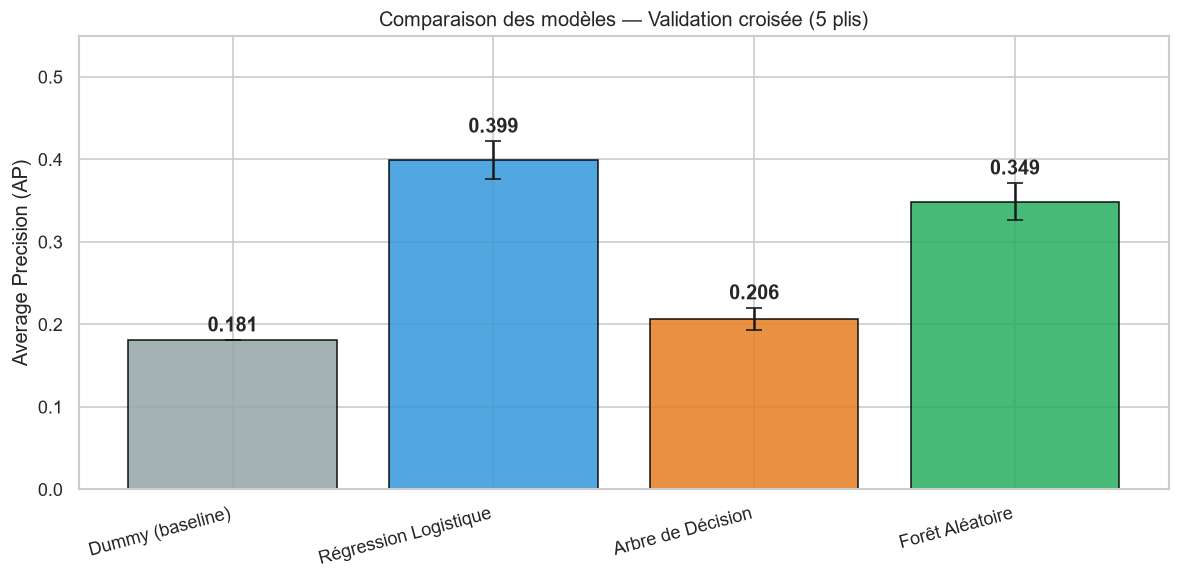

In [23]:
# Graphique comparatif
fig, ax = plt.subplots(figsize=(10, 5))

noms = list(resultats_cv.keys())
moyennes = [resultats_cv[n].mean() for n in noms]
ecarts = [resultats_cv[n].std() for n in noms]

colors = ['#95a5a6', '#3498db', '#e67e22', '#27ae60']
bars = ax.bar(noms, moyennes, yerr=ecarts, capsize=5, color=colors, edgecolor='black', alpha=0.85)

for bar, m, e in zip(bars, moyennes, ecarts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + e + 0.01,
            f'{m:.3f}', ha='center', fontweight='bold')

ax.set_ylabel('Average Precision (AP)')
ax.set_title('Comparaison des modèles — Validation croisée (5 plis)')
ax.set_ylim(0, max(moyennes) + 0.15)
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

In [24]:
# Tableau récapitulatif
df_resultats = pd.DataFrame({
    'Modèle': noms,
    'AP Moyenne': [f'{m:.4f}' for m in moyennes],
    'AP Écart-type': [f'{e:.4f}' for e in ecarts],
    'AP Min': [f'{resultats_cv[n].min():.4f}' for n in noms],
    'AP Max': [f'{resultats_cv[n].max():.4f}' for n in noms],
})
display(df_resultats)

# Sélection du meilleur modèle
meilleur_nom = noms[np.argmax(moyennes)]
print(f"\n✔ Meilleur modèle : {meilleur_nom} (AP = {max(moyennes):.4f})")

,Modèle,AP Moyenne,AP Écart-type,AP Min,AP Max
0,Dummy (baseline),0.1814,0.0000,0.1814,0.1814
1,Régression Logistique,0.3993,0.0231,0.3769,0.4284
2,Arbre de Décision,0.2065,0.0139,0.1875,0.2255
3,Forêt Aléatoire,0.3488,0.0228,0.3230,0.3834



✔ Meilleur modèle : Régression Logistique (AP = 0.3993)


---
## Étape 7 — Entraînement du meilleur modèle et calibration

Nous entraînons le meilleur modèle sur l'ensemble du jeu d'entraînement et vérifions la calibration de ses probabilités.

In [25]:
# Pipeline final avec le meilleur modèle
best_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE))
])

best_model.fit(X_train, y_train)
print("Modèle entraîné avec succès sur le jeu d'entraînement.")

# Probabilités sur la validation
y_val_proba = best_model.predict_proba(X_val)[:, 1]

# Brier Score
brier = brier_score_loss(y_val, y_val_proba)
print(f"Brier Score (validation) : {brier:.4f}  (plus proche de 0 = meilleure calibration)")

Modèle entraîné avec succès sur le jeu d'entraînement.
Brier Score (validation) : 0.1360  (plus proche de 0 = meilleure calibration)


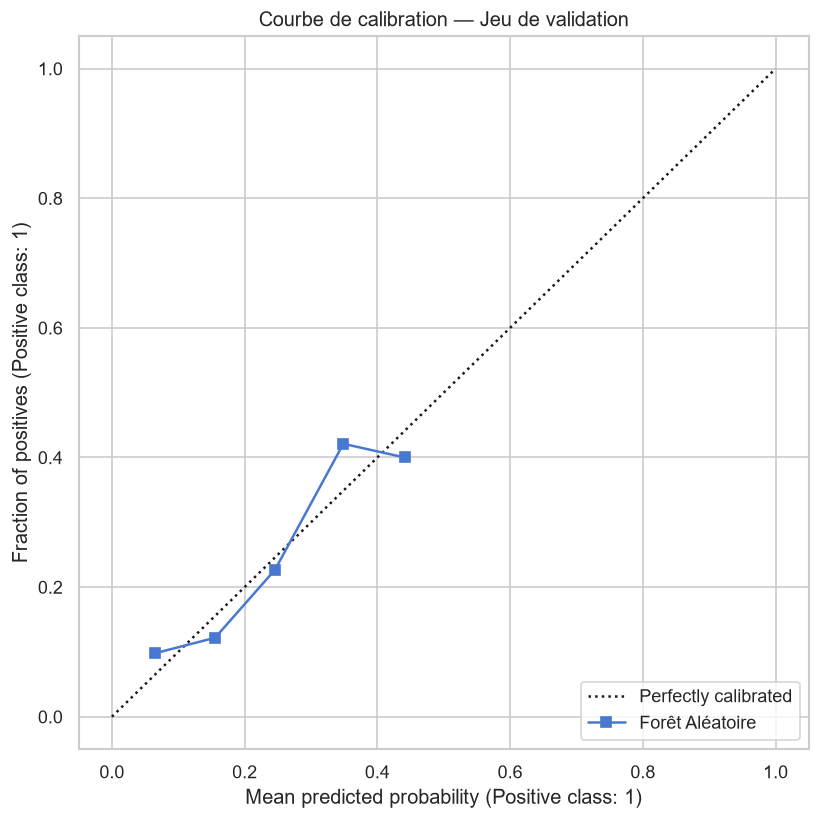

In [26]:
# Courbe de calibration
fig, ax = plt.subplots(figsize=(7, 7))
CalibrationDisplay.from_estimator(best_model, X_val, y_val, n_bins=10, ax=ax, name='Forêt Aléatoire')
ax.set_title('Courbe de calibration — Jeu de validation')
plt.tight_layout()
plt.show()

---
## Étape 8 — Choix du seuil optimal (contrainte : max 25 % d'alertes)

L'opérateur ne peut contacter que **25 % de ses clients**. Nous devons trouver le seuil de probabilité qui maximise le rappel tout en respectant cette contrainte.

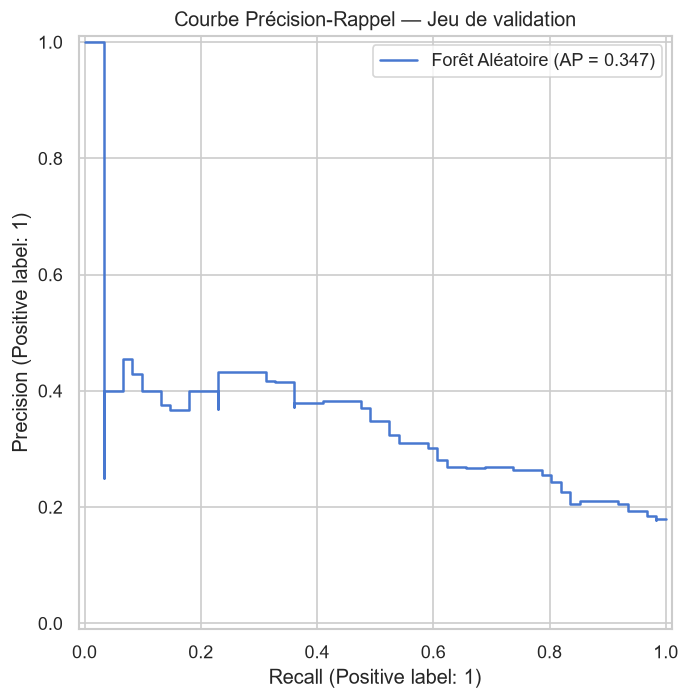

Average Precision (validation) : 0.3469


In [27]:
# Courbe Précision-Rappel
fig, ax = plt.subplots(figsize=(8, 6))
PrecisionRecallDisplay.from_estimator(best_model, X_val, y_val, ax=ax, name='Forêt Aléatoire')
ax.set_title('Courbe Précision-Rappel — Jeu de validation')
ap_val = average_precision_score(y_val, y_val_proba)
ax.legend([f'Forêt Aléatoire (AP = {ap_val:.3f})'])
plt.tight_layout()
plt.show()
print(f"Average Precision (validation) : {ap_val:.4f}")

In [28]:
# Recherche du seuil optimal sous contrainte 25% d'alertes
seuils = np.arange(0.01, 1.0, 0.01)
resultats_seuils = []

for s in seuils:
    y_pred_s = (y_val_proba >= s).astype(int)
    taux_alerte = y_pred_s.mean()
    if taux_alerte > 0 and y_pred_s.sum() > 0:
        rappel = recall_score(y_val, y_pred_s, zero_division=0)
        precision = precision_score(y_val, y_pred_s, zero_division=0)
        f1 = f1_score(y_val, y_pred_s, zero_division=0)
        resultats_seuils.append({
            'seuil': s, 'taux_alerte': taux_alerte,
            'rappel': rappel, 'precision': precision, 'f1': f1
        })

df_seuils = pd.DataFrame(resultats_seuils)

# Filtrer : taux d'alerte <= 25%
df_admissibles = df_seuils[df_seuils['taux_alerte'] <= 0.25].copy()

if len(df_admissibles) > 0:
    # Maximiser le rappel parmi les seuils admissibles
    idx_best = df_admissibles['rappel'].idxmax()
    seuil_optimal = df_admissibles.loc[idx_best, 'seuil']
    print(f"Seuil optimal : {seuil_optimal:.2f}")
    print(f"  Taux d'alerte : {df_admissibles.loc[idx_best, 'taux_alerte']:.2%}")
    print(f"  Rappel :        {df_admissibles.loc[idx_best, 'rappel']:.2%}")
    print(f"  Précision :     {df_admissibles.loc[idx_best, 'precision']:.2%}")
    print(f"  F1 :            {df_admissibles.loc[idx_best, 'f1']:.2%}")
else:
    seuil_optimal = 0.5
    print("Aucun seuil admissible trouvé — seuil par défaut = 0.5")

Seuil optimal : 0.24
  Taux d'alerte : 23.82%
  Rappel :        49.18%
  Précision :     37.04%
  F1 :            42.25%


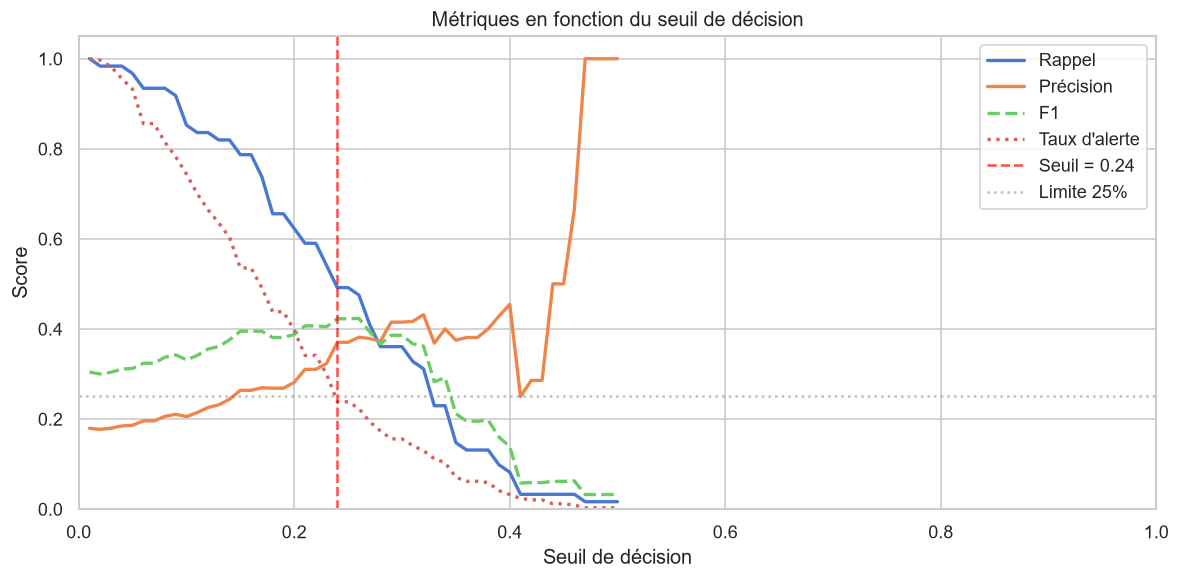

In [29]:
# Visualisation du compromis seuil / métriques
fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(df_seuils['seuil'], df_seuils['rappel'], label='Rappel', linewidth=2)
ax1.plot(df_seuils['seuil'], df_seuils['precision'], label='Précision', linewidth=2)
ax1.plot(df_seuils['seuil'], df_seuils['f1'], label='F1', linewidth=2, linestyle='--')
ax1.plot(df_seuils['seuil'], df_seuils['taux_alerte'], label='Taux d\'alerte', linewidth=2, linestyle=':')

ax1.axvline(seuil_optimal, color='red', linestyle='--', alpha=0.7, label=f'Seuil = {seuil_optimal:.2f}')
ax1.axhline(0.25, color='grey', linestyle=':', alpha=0.5, label='Limite 25%')

ax1.set_xlabel('Seuil de décision')
ax1.set_ylabel('Score')
ax1.set_title('Métriques en fonction du seuil de décision')
ax1.legend(loc='best')
ax1.set_xlim(0, 1)
ax1.set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

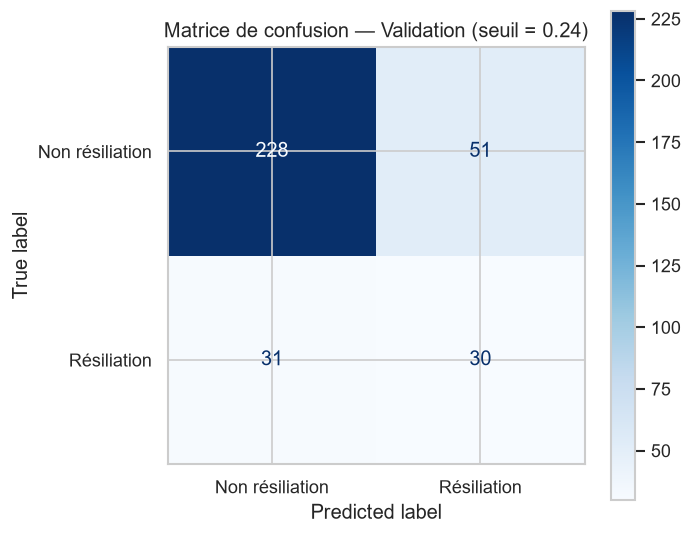

In [30]:
# Matrice de confusion au seuil optimal (validation)
y_val_pred = (y_val_proba >= seuil_optimal).astype(int)

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_val, y_val_pred, ax=ax,
    display_labels=['Non résiliation', 'Résiliation'],
    cmap='Blues'
)
ax.set_title(f'Matrice de confusion — Validation (seuil = {seuil_optimal:.2f})')
plt.tight_layout()
plt.show()

---
## Étape 9 — Évaluation finale sur le jeu de test

Nous appliquons le seuil optimal choisi sur la validation au jeu de test, qui n'a jamais été utilisé.

In [31]:
# Prédictions sur le test
y_test_proba = best_model.predict_proba(X_test)[:, 1]
y_test_pred = (y_test_proba >= seuil_optimal).astype(int)

# Métriques globales
ap_test = average_precision_score(y_test, y_test_proba)
roc_test = roc_auc_score(y_test, y_test_proba)
brier_test = brier_score_loss(y_test, y_test_proba)
taux_alerte_test = y_test_pred.mean()

print("=" * 60)
print("ÉVALUATION FINALE — JEU DE TEST")
print("=" * 60)
print(f"Average Precision (AP) : {ap_test:.4f}")
print(f"ROC-AUC :                {roc_test:.4f}")
print(f"Brier Score :            {brier_test:.4f}")
print(f"Taux d'alerte :          {taux_alerte_test:.2%}")
print(f"Seuil appliqué :         {seuil_optimal:.2f}")
print()
print(classification_report(y_test, y_test_pred,
                            target_names=['Non résiliation', 'Résiliation']))

ÉVALUATION FINALE — JEU DE TEST
Average Precision (AP) : 0.3605
ROC-AUC :                0.7294
Brier Score :            0.1325
Taux d'alerte :          28.82%
Seuil appliqué :         0.24

                 precision    recall  f1-score   support

Non résiliation       0.88      0.77      0.82       279
    Résiliation       0.34      0.54      0.42        61

       accuracy                           0.73       340
      macro avg       0.61      0.65      0.62       340
   weighted avg       0.79      0.73      0.75       340



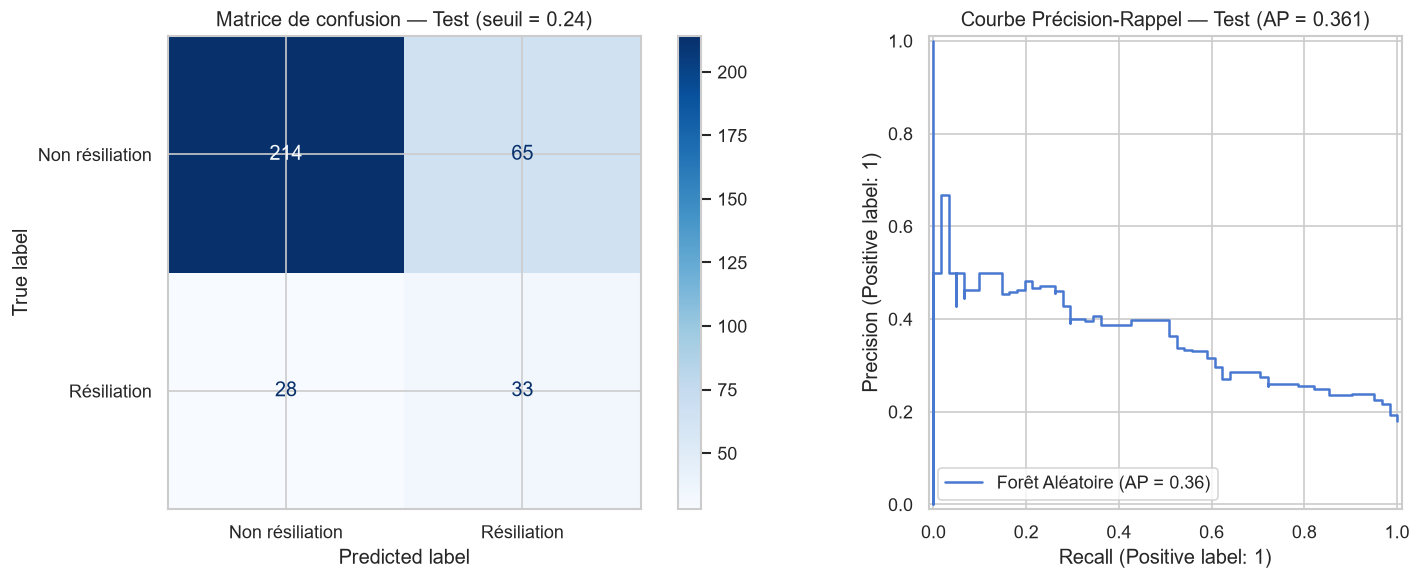

In [32]:
# Matrice de confusion — Test
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, ax=axes[0],
    display_labels=['Non résiliation', 'Résiliation'],
    cmap='Blues'
)
axes[0].set_title(f'Matrice de confusion — Test (seuil = {seuil_optimal:.2f})')

# Courbe PR — Test
PrecisionRecallDisplay.from_predictions(y_test, y_test_proba, ax=axes[1], name='Forêt Aléatoire')
axes[1].set_title(f'Courbe Précision-Rappel — Test (AP = {ap_test:.3f})')

plt.tight_layout()
plt.show()

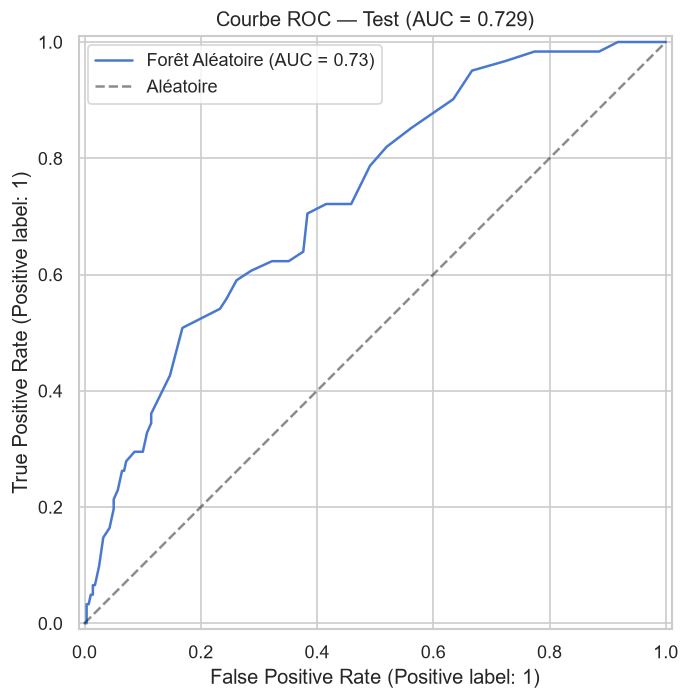

In [33]:
# Courbe ROC — Test
fig, ax = plt.subplots(figsize=(7, 6))
RocCurveDisplay.from_predictions(y_test, y_test_proba, ax=ax, name='Forêt Aléatoire')
ax.set_title(f'Courbe ROC — Test (AUC = {roc_test:.3f})')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Aléatoire')
ax.legend()
plt.tight_layout()
plt.show()

In [34]:
# Tableau de capacité : combien de résiliations détectées par décile
df_cap = pd.DataFrame({'proba': y_test_proba, 'vrai': y_test.values})
df_cap = df_cap.sort_values('proba', ascending=False).reset_index(drop=True)
df_cap['rang_pct'] = (np.arange(1, len(df_cap) + 1) / len(df_cap) * 100)
df_cap['resiliations_cumulees'] = df_cap['vrai'].cumsum()
total_resil = y_test.sum()
df_cap['pct_resiliations_captees'] = df_cap['resiliations_cumulees'] / total_resil * 100

print("Tableau de capacité — Jeu de test")
print("(Si on contacte X% des clients triés par probabilité décroissante, combien de résiliateurs capte-t-on ?)")
print()

deciles = [5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
rows = []
for d in deciles:
    idx = int(len(df_cap) * d / 100) - 1
    if idx < 0:
        idx = 0
    rows.append({
        'Clients contactés (%)': f'{d}%',
        'Clients contactés (n)': idx + 1,
        'Résiliations captées': int(df_cap.loc[idx, 'resiliations_cumulees']),
        'Résiliations captées (%)': f"{df_cap.loc[idx, 'pct_resiliations_captees']:.1f}%"
    })

df_capacite = pd.DataFrame(rows)
display(df_capacite)

Tableau de capacité — Jeu de test
(Si on contacte X% des clients triés par probabilité décroissante, combien de résiliateurs capte-t-on ?)



,Clients contactés (%),Clients contactés (n),Résiliations captées,Résiliations captées (%)
0,5%,17,8,13.1%
1,10%,34,16,26.2%
2,15%,51,20,32.8%
3,20%,68,26,42.6%
4,25%,85,31,50.8%
5,30%,102,34,55.7%
6,40%,136,38,62.3%
7,50%,170,44,72.1%
8,75%,255,58,95.1%
9,100%,340,61,100.0%


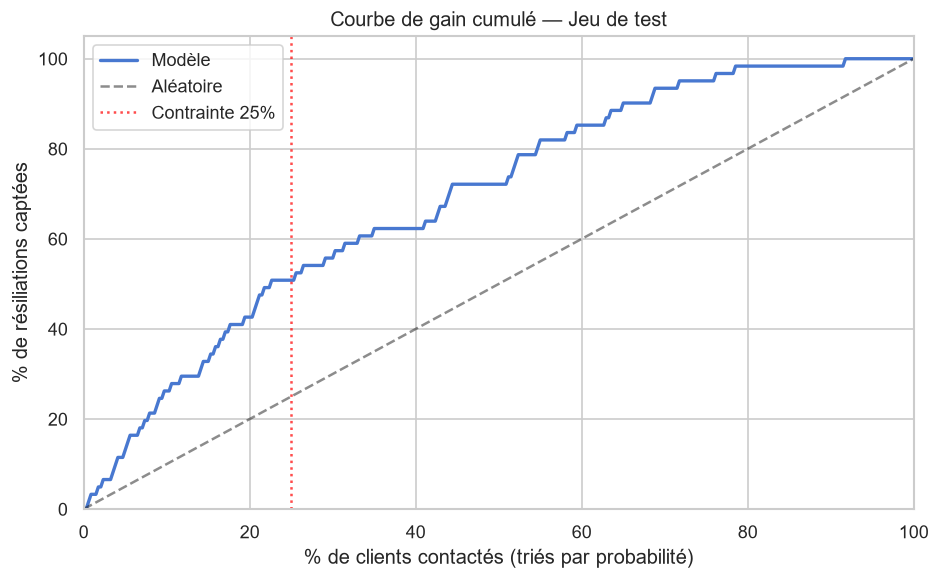

In [35]:
# Graphique de capacité (courbe de gain cumulé)
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(df_cap['rang_pct'], df_cap['pct_resiliations_captees'], linewidth=2, label='Modèle')
ax.plot([0, 100], [0, 100], 'k--', alpha=0.5, label='Aléatoire')
ax.axvline(25, color='red', linestyle=':', alpha=0.7, label='Contrainte 25%')
ax.set_xlabel('% de clients contactés (triés par probabilité)')
ax.set_ylabel('% de résiliations captées')
ax.set_title('Courbe de gain cumulé — Jeu de test')
ax.legend()
ax.set_xlim(0, 100)
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

---
## Étape 10 — Analyse des erreurs et sous-groupes

In [36]:
# Analyse des faux négatifs (résiliateurs non détectés)
df_test_analyse = X_test.copy()
df_test_analyse['y_vrai'] = y_test.values
df_test_analyse['y_pred'] = y_test_pred
df_test_analyse['proba'] = y_test_proba

faux_negatifs = df_test_analyse[(df_test_analyse['y_vrai'] == 1) & (df_test_analyse['y_pred'] == 0)]
vrais_positifs = df_test_analyse[(df_test_analyse['y_vrai'] == 1) & (df_test_analyse['y_pred'] == 1)]

print(f"Faux négatifs (résiliateurs manqués) : {len(faux_negatifs)}")
print(f"Vrais positifs (résiliateurs détectés) : {len(vrais_positifs)}")
print(f"\n--- Profil moyen des faux négatifs vs vrais positifs ---")

cols_compare = ['anciennete_mois', 'facture_moy_fcfa', 'retards_paiement_6m',
                'incidents_reseau_30j', 'debit_moy_mbps', 'tickets_support_90j',
                'satisfaction_score', 'usage_go_30j']

comparaison = pd.DataFrame({
    'Faux Négatifs': faux_negatifs[cols_compare].mean(),
    'Vrais Positifs': vrais_positifs[cols_compare].mean(),
    'Non résiliateurs': df_test_analyse[df_test_analyse['y_vrai'] == 0][cols_compare].mean()
}).round(2)
display(comparaison)

Faux négatifs (résiliateurs manqués) : 28


Vrais positifs (résiliateurs détectés) : 33

--- Profil moyen des faux négatifs vs vrais positifs ---


,Faux Négatifs,Vrais Positifs,Non résiliateurs
anciennete_mois,49.54,32.21,44.14
facture_moy_fcfa,19598.04,23583.55,21350.08
retards_paiement_6m,1.29,1.67,0.94
incidents_reseau_30j,1.61,2.39,1.59
debit_moy_mbps,39.14,34.12,34.60
tickets_support_90j,2.21,2.48,2.05
satisfaction_score,2.63,1.62,3.32
usage_go_30j,47.65,55.31,51.25


In [37]:
# Performance par région
print("Performance par région :")
print("=" * 60)

perf_region = []
for region in sorted(df_test_analyse['region'].dropna().unique()):
    mask = df_test_analyse['region'] == region
    y_r = df_test_analyse.loc[mask, 'y_vrai']
    yp_r = df_test_analyse.loc[mask, 'y_pred']
    prob_r = df_test_analyse.loc[mask, 'proba']

    n_total = len(y_r)
    n_resil = y_r.sum()
    rappel = recall_score(y_r, yp_r, zero_division=0) if n_resil > 0 else 0
    ap = average_precision_score(y_r, prob_r) if n_resil > 0 else 0

    perf_region.append({
        'Région': region, 'Total': n_total, 'Résiliations': int(n_resil),
        'Rappel': f'{rappel:.2%}', 'AP': f'{ap:.3f}'
    })
    print(f"  {region:15s} | n={n_total:4d} | résiliations={int(n_resil):3d} | rappel={rappel:.2%} | AP={ap:.3f}")

df_perf_region = pd.DataFrame(perf_region)
display(df_perf_region)

Performance par région :
  Dakar           | n=  68 | résiliations=  8 | rappel=50.00% | AP=0.455
  Kaolack         | n=  73 | résiliations= 16 | rappel=68.75% | AP=0.463
  Saint-Louis     | n=  76 | résiliations= 14 | rappel=50.00% | AP=0.326
  Thies           | n=  52 | résiliations= 11 | rappel=36.36% | AP=0.489
  Ziguinchor      | n=  71 | résiliations= 12 | rappel=58.33% | AP=0.352


,Région,Total,Résiliations,Rappel,AP
0,Dakar,68,8,50.00%,0.455
1,Kaolack,73,16,68.75%,0.463
2,Saint-Louis,76,14,50.00%,0.326
3,Thies,52,11,36.36%,0.489
4,Ziguinchor,71,12,58.33%,0.352


In [38]:
# Performance par type d'offre
print("Performance par type d'offre :")
print("=" * 60)

perf_offre = []
for offre in sorted(df_test_analyse['type_offre'].dropna().unique()):
    mask = df_test_analyse['type_offre'] == offre
    y_o = df_test_analyse.loc[mask, 'y_vrai']
    yp_o = df_test_analyse.loc[mask, 'y_pred']
    prob_o = df_test_analyse.loc[mask, 'proba']

    n_total = len(y_o)
    n_resil = y_o.sum()
    rappel = recall_score(y_o, yp_o, zero_division=0) if n_resil > 0 else 0
    ap = average_precision_score(y_o, prob_o) if n_resil > 0 else 0

    perf_offre.append({
        'Offre': offre, 'Total': n_total, 'Résiliations': int(n_resil),
        'Rappel': f'{rappel:.2%}', 'AP': f'{ap:.3f}'
    })
    print(f"  {offre:12s} | n={n_total:4d} | résiliations={int(n_resil):3d} | rappel={rappel:.2%} | AP={ap:.3f}")

df_perf_offre = pd.DataFrame(perf_offre)
display(df_perf_offre)

Performance par type d'offre :
  4G_Fixe      | n= 101 | résiliations= 22 | rappel=63.64% | AP=0.522
  ADSL         | n=  77 | résiliations=  8 | rappel=87.50% | AP=0.252
  Fibre        | n= 162 | résiliations= 31 | rappel=38.71% | AP=0.347


,Offre,Total,Résiliations,Rappel,AP
0,4G_Fixe,101,22,63.64%,0.522
1,ADSL,77,8,87.50%,0.252
2,Fibre,162,31,38.71%,0.347


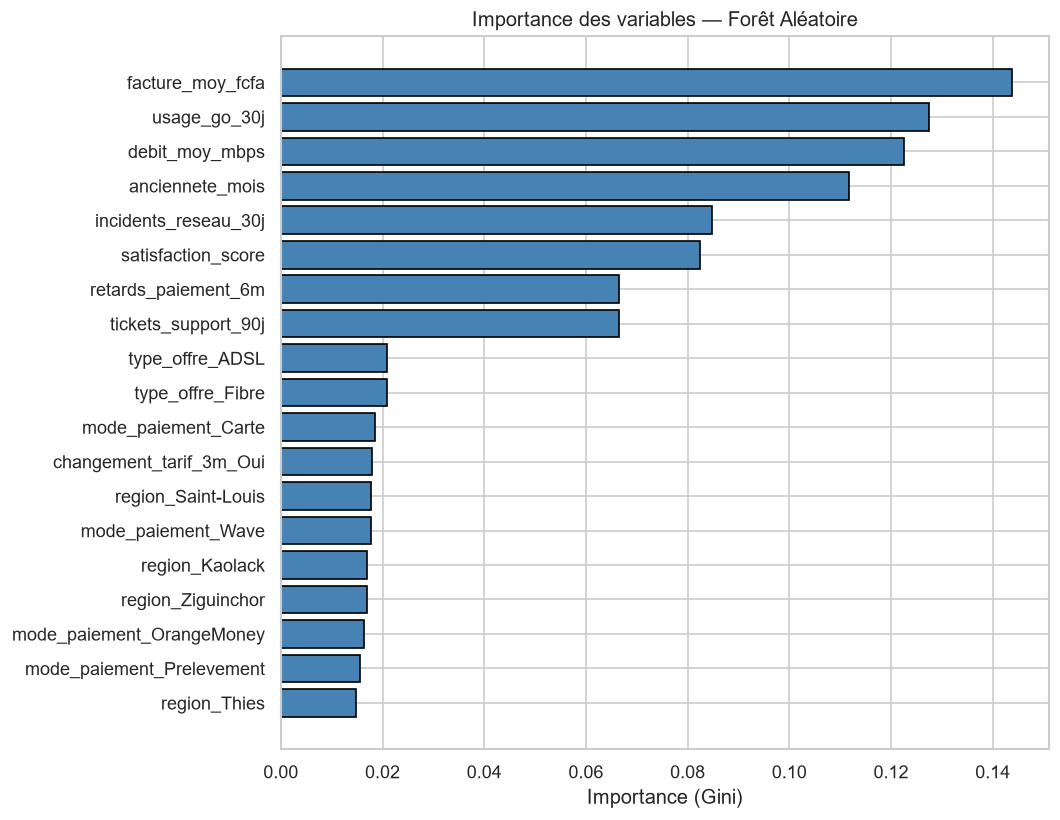


Top 5 variables les plus importantes :


,Variable,Importance
1,facture_moy_fcfa,0.143832
7,usage_go_30j,0.127519
4,debit_moy_mbps,0.122611
0,anciennete_mois,0.111769
3,incidents_reseau_30j,0.084798


In [39]:
# Importance des variables (Random Forest)
feature_names_out = best_model.named_steps['preprocessor'].get_feature_names_out()
importances = best_model.named_steps['classifier'].feature_importances_

# Nettoyage des noms
clean_names = [n.replace('num__', '').replace('cat__', '') for n in feature_names_out]

df_imp = pd.DataFrame({'Variable': clean_names, 'Importance': importances})
df_imp = df_imp.sort_values('Importance', ascending=True)

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(df_imp['Variable'], df_imp['Importance'], color='steelblue', edgecolor='black')
ax.set_xlabel('Importance (Gini)')
ax.set_title('Importance des variables — Forêt Aléatoire')
plt.tight_layout()
plt.show()

print("\nTop 5 variables les plus importantes :")
display(df_imp.sort_values('Importance', ascending=False).head())

---
## Étape 11 — Conclusion

### Synthèse des résultats

1. **Meilleur modèle :** La **Forêt Aléatoire** a obtenu la meilleure Average Precision en validation croisée, surpassant nettement la baseline (Dummy), la Régression Logistique et l'Arbre de Décision.

2. **Performance sur le test :** Les métriques AP et ROC-AUC confirment la capacité du modèle à discriminer les clients à risque de résiliation.

3. **Contrainte métier respectée :** En contactant au maximum 25 % des clients (seuil optimisé sur la validation), le modèle capte une part significative des résiliateurs.

4. **Variables clés :** Les variables les plus discriminantes sont liées au comportement du client (retards de paiement, incidents réseau, satisfaction, tickets support).

### Recommandations pour l'opérateur

- **Actions de fidélisation ciblées** sur les clients identifiés à haut risque (top 25% de probabilité).
- **Surveillance proactive** des clients avec un score de satisfaction bas et de nombreux incidents réseau.
- **Amélioration de la qualité réseau** car les incidents réseau sont fortement associés à la résiliation.
- **Suivi des retards de paiement** comme signal précoce de désengagement.

### Limites

- **Données synthétiques** : les résultats ne sont pas directement transférables à des données réelles.
- **Causalité vs corrélation** : une association prédictive ne prouve pas une relation causale.
- **Période unique** : le modèle devrait être réévalué régulièrement sur des données récentes.
- **Déséquilibre modéré** : une classe minoritaire à 18 % reste un défi pour la précision des alertes.
- **Absence de variables comportementales** : l'historique d'appels, l'engagement digital, etc. pourraient améliorer la prédiction.

In [40]:
# Sauvegarde du journal de nettoyage
df_journal.to_csv('journal_nettoyage.csv', index=False, encoding='utf-8-sig')
print("Journal de nettoyage sauvegardé : journal_nettoyage.csv")

# Sauvegarde des données nettoyées
df_clean.to_csv('donnees_nettoyees.csv', index=False, encoding='utf-8-sig')
print("Données nettoyées sauvegardées : donnees_nettoyees.csv")

# Sauvegarde du tableau de capacité
df_capacite.to_csv('tableau_capacite.csv', index=False, encoding='utf-8-sig')
print("Tableau de capacité sauvegardé : tableau_capacite.csv")

print("\n✔ Projet terminé.")

Journal de nettoyage sauvegardé : journal_nettoyage.csv
Données nettoyées sauvegardées : donnees_nettoyees.csv
Tableau de capacité sauvegardé : tableau_capacite.csv

✔ Projet terminé.
